# 購入履歴のつながりから、推薦する商品を選ぶ

## 概要

『マーケティングサイエンスの理論と実践』第12章「つながりを活かして推薦する」では、購入履歴をグラフで表し、GNN（グラフニューラルネットワーク）で商品を推薦する方法を扱う。この記事は、実務の課題、グラフの理論、NGCFとLightGCNの実装、評価結果の順に本章を紹介する。

### 実行環境

仮想環境は **wa-src(3.14.6)**、Pythonは **3.14.6** である。NumPy、Matplotlib、PyTorchを使う。上から順に実行すると、模擬データの作成から推薦まで確認できる。図は `12_nb_files` にSVGで保存する。小数の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
from base64 import b64encode
from copy import deepcopy
from importlib.metadata import version
from io import BytesIO
from pathlib import Path
from pprint import pprint
import platform

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, ScalarFormatter, MaxNLocator
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import Latex, display

# ノートブックのフォルダー、またはリポジトリ直下から実行する。
BASE = Path.cwd()
if (BASE / "blog/12/12_nb.ipynb").exists():
    BASE = BASE / "blog/12"
FIG_DIR = BASE / "12_nb_files"
FIG_DIR.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロも残して有効数字3桁で表示する。"""
    return format(float(value), "#.3g").removesuffix(".")


def show_math(tex):
    # 重要式の原稿は \( ... \)。出力では二重の区切りを避ける。
    tex = tex.strip()
    if tex.startswith(r"\(") and tex.endswith(r"\)"):
        tex = tex[2:-2].strip()
    display(Latex("$$\n" + tex + "\n$$"))


def save_svg(fig, filename):
    """SVGを保存し、同じ図をノートブックにも埋め込む。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(FuncFormatter(
                    lambda value, _: str(int(value))
                    if float(value).is_integer() else sig3(value)
                ))
    path = FIG_DIR / filename
    fig.savefig(path, format="svg", bbox_inches="tight")
    # SVG非対応のビューアー向けに、出力欄だけPNGも埋め込む。
    preview = BytesIO()
    fig.savefig(preview, format="png", dpi=120, bbox_inches="tight")
    plt.close(fig)
    display({"image/svg+xml": path.read_text(encoding="utf-8"),
             "image/png": b64encode(preview.getvalue()).decode("ascii")}, raw=True)


def heatmap(ax, matrix, rows, cols, title, vmax=None, integer=False):
    """小さな行列を、数値付きのヒートマップで確認する。"""
    limit = float(np.max(matrix)) if vmax is None else vmax
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(limit, 1.00e-12), aspect="auto")
    ax.set(xticks=range(len(cols)), xticklabels=cols,
           yticks=range(len(rows)), yticklabels=rows, title=title)
    for (row, col), value in np.ndenumerate(matrix):
        label = str(int(value)) if integer or value == 0 else sig3(value)
        ax.text(col, row, label, ha="center", va="center", fontsize=9,
                color="white" if value > limit * 0.550 else "black")


np.set_printoptions(formatter={"float_kind": sig3})
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for candidate in ("Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "Yu Gothic"):
    if candidate in available_fonts:
        plt.rcParams["font.family"] = candidate
        break
plt.rcParams.update({"font.size": 11, "axes.unicode_minus": False,
                     "svg.fonttype": "path", "svg.hashsalt": "blog12"})
COLORS = ["#3274A1", "#D58B27", "#419578"]
torch.set_num_threads(1)
torch.manual_seed(123)

print("仮想環境：wa-src(3.14.6)")
print(f"Python：{platform.python_version()} / OS：{platform.system()}")
for package in ("numpy", "matplotlib", "torch"):
    print(f"{package}：{version(package)}")

仮想環境：wa-src(3.14.6)
Python：3.14.6 / OS：Darwin
numpy：2.4.6
matplotlib：3.11.2
torch：2.15.0


## 1. 履歴の少ないユーザーに何を推薦するか

ある商品を購入した人には、次に何を勧めればよいか。本人の履歴が少なくても、同じ商品を買った別のユーザーの履歴は手がかりになる。本章の導入では、知人からの紹介や友人同士の似た購買行動を例に、こうしたつながりを扱う必要性を説明している。

基本的な行列分解は購入履歴から共通の傾向を学ぶ。LightGBMでは、友人の購入割合などを特徴量に変えて使える。GNNは、つながる相手の情報を集め、処理を重ねて先の情報も取り込む。

ただし、購入履歴がまったくない新規ユーザーには、購入関係だけでは情報が届かない。履歴が少ない場合とは分けて考える必要がある。私なら、全体の精度だけでなく、履歴件数ごとの結果も確認したい。本章の実装で使うのはユーザーと商品の購入関係であり、友人関係は入力しない。

## 2. グラフから好みを学ぶ仕組み

### 2.1 購入関係を行列で表す

グラフ$G=(V,E)$の$V$はノード、$E$は辺の集合である。ユーザーと商品を別の集合とし、購入した組だけを結ぶと二部グラフになる。購入は一方向の行動だが、情報を両方向に伝えるため、ここでは無向グラフとして扱う。

購入行列$\mathbf{R}$の行をユーザー、列を商品とする。購入なら1、それ以外なら0である。隣接行列$\mathbf{A}$では、ユーザー同士と商品同士のブロックを零行列にする。以下は説明用の3人・4商品の例である。

<IPython.core.display.Latex object>

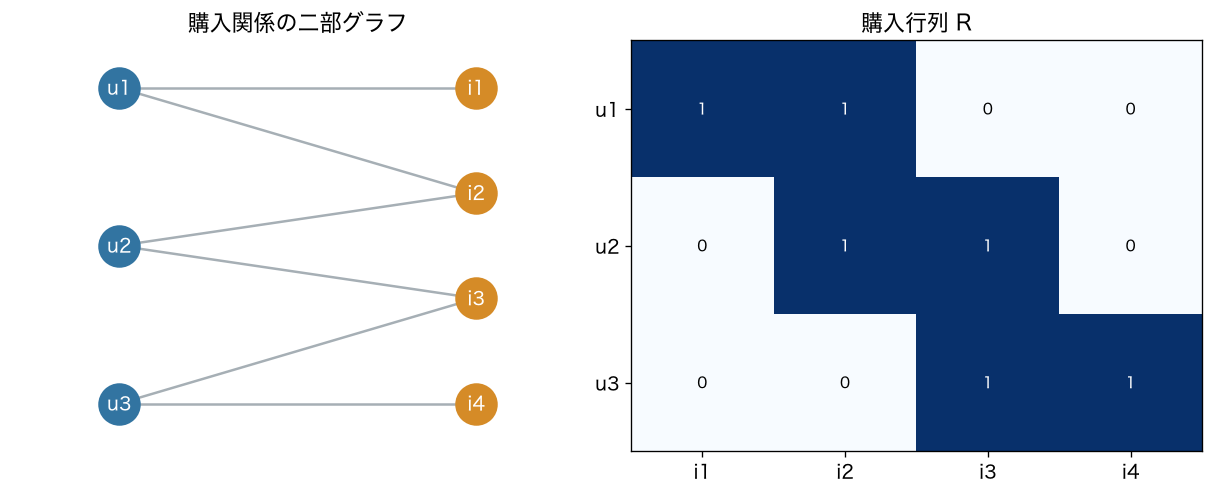

In [2]:
show_math(r"""\(
\mathbf{R}=\begin{pmatrix}1&1&0&0\\0&1&1&0\\0&0&1&1\end{pmatrix},
\qquad
\mathbf{A}=\begin{pmatrix}\mathbf{0}&\mathbf{R}\\
\mathbf{R}^{\top}&\mathbf{0}\end{pmatrix}.
\)""")

R = np.array([[1, 1, 0, 0], [0, 1, 1, 0], [0, 0, 1, 1]])
A = np.block([[np.zeros((3, 3)), R], [R.T, np.zeros((4, 4))]])
users = ["u1", "u2", "u3"]
items = ["i1", "i2", "i3", "i4"]
nodes = users + items

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
user_y = np.linspace(1, 0, len(users))
item_y = np.linspace(1, 0, len(items))
for u, i in np.argwhere(R == 1):
    axes[0].plot([0, 1], [user_y[u], item_y[i]], color="#A6AFB5", zorder=1)
for x, yy, names, color in ((0, user_y, users, COLORS[0]),
                            (1, item_y, items, COLORS[1])):
    axes[0].scatter(np.full(len(yy), x), yy, s=600, color=color, zorder=2)
    for y, label in zip(yy, names):
        axes[0].text(x, y, label, ha="center", va="center", color="white")
axes[0].set(title="購入関係の二部グラフ", xlim=(-0.300, 1.30), ylim=(-0.150, 1.15))
axes[0].axis("off")
heatmap(axes[1], R, users, items, "購入行列 R", integer=True)
save_svg(fig, "01_purchase_graph.svg")

### 2.2 接続数に応じて重みを調整する

ノード$v$の接続数を$d_v$とし、対角に並べた行列を$\mathbf{D}$とする。グラフラプラシアンは$\mathbf{L}=\mathbf{D}-\mathbf{A}$である。次数が正なら、左右から$\mathbf{D}^{-1/2}$を掛けて次のように変形できる。

<IPython.core.display.Latex object>

{'各ノードの次数': [2, 2, 2, 1, 2, 2, 1]}


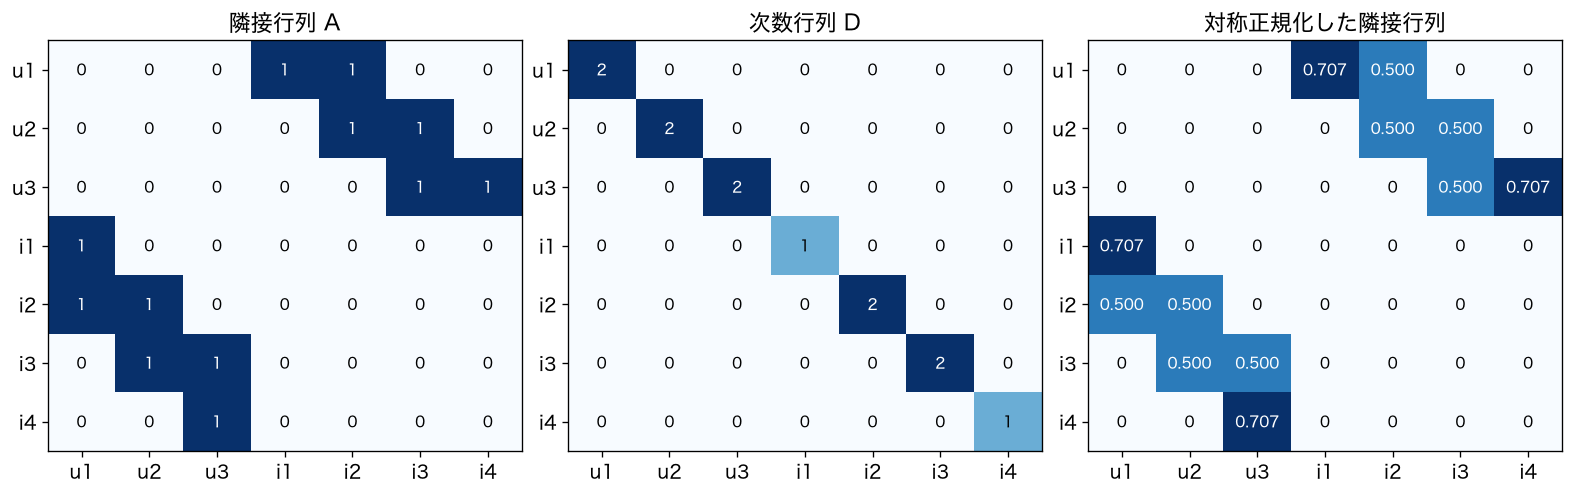

In [3]:
show_math(r"""\(
\begin{aligned}
d_v&=\sum_w A_{vw},\qquad \mathbf{D}=\operatorname{diag}(d_1,\ldots,d_7),\\
\widetilde{\mathbf{L}}
&=\mathbf{D}^{-1/2}(\mathbf{D}-\mathbf{A})\mathbf{D}^{-1/2}\\
&=\mathbf{D}^{-1/2}\mathbf{D}\mathbf{D}^{-1/2}
-\mathbf{D}^{-1/2}\mathbf{A}\mathbf{D}^{-1/2}\\
&=\mathbf{I}-\widetilde{\mathbf{A}},\qquad
\widetilde{\mathbf{A}}=\mathbf{D}^{-1/2}\mathbf{A}\mathbf{D}^{-1/2},\\
\widetilde{A}_{vw}&=\frac{A_{vw}}{\sqrt{d_v}\sqrt{d_w}}.
\end{aligned}
\)""")

degree = A.sum(axis=1)
# 孤立ノードは逆数を0とし、ゼロ除算を避ける。
inverse_sqrt = np.divide(1, np.sqrt(degree), out=np.zeros_like(degree), where=degree > 0)
A_norm = inverse_sqrt[:, None] * A * inverse_sqrt[None, :]
pprint({"各ノードの次数": degree.astype(int).tolist()})

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
heatmap(axes[0], A, nodes, nodes, "隣接行列 A", integer=True)
heatmap(axes[1], np.diag(degree), nodes, nodes, "次数行列 D", integer=True)
heatmap(axes[2], A_norm, nodes, nodes, "対称正規化した隣接行列")
save_svg(fig, "02_graph_matrices.svg")

図2では、辺の位置は変わらず重みだけが変わる。例えば$u_1$と$i_1$の次数は2と1なので、重みは$1/\sqrt{2\times1}\approx0.707$となる。接続数の多いノードの影響を調整する処理である。

### 2.3 GCNとメッセージパッシング

各ノードを数値ベクトルで表したものを埋め込みという。GCNは自己ループを加え、隣接ノードと自分の埋め込みを集め、重み行列$\mathbf{W}$と活性化関数$\phi$で変換する。$\mathbf{H}^{(l)}$は全ノードの$l$層目の埋め込みである。

In [4]:
show_math(r"""\(
\begin{aligned}
\widehat{\mathbf{A}}&=\mathbf{A}+\mathbf{I},\qquad
\widehat{D}_{vv}=\sum_w\widehat{A}_{vw},\\
\overline{\mathbf{A}}&=\widehat{\mathbf{D}}^{-1/2}
\widehat{\mathbf{A}}\widehat{\mathbf{D}}^{-1/2},\\
\mathbf{H}^{(l+1)}&=\phi\!\left(\overline{\mathbf{A}}
\mathbf{H}^{(l)}\mathbf{W}^{(l)}\right).
\end{aligned}
\)""")

<IPython.core.display.Latex object>

この情報交換をメッセージパッシングと呼ぶ。集約には和・平均・最大値などが使われる。1層で隣、2層で最大2本の辺をたどった先まで情報が届く。ただし、層を増やすと埋め込みの違いが小さくなる過平滑化が起こる場合があり、深ければよいわけではない。

### 2.4 NGCFは集約と要素積を使う

本章のNGCFでは、行正規化後に自己ループを加えた$\mathbf{S}$を使う。集約結果$\mathbf{M}$と自身の埋め込み$\mathbf{E}$の要素積$\odot$も計算する。$\mathbf{W}_1,\mathbf{W}_2$と調整値$\mathbf{b}_1,\mathbf{b}_2$は学習する値である。

In [5]:
show_math(r"""\(
\begin{aligned}
\mathbf{S}&=\mathbf{D}^{-1}\mathbf{A}+\mathbf{I},\qquad
\mathbf{M}=\mathbf{S}\mathbf{E}^{(l)},\\
\mathbf{Z}&=\mathbf{M}\mathbf{W}_1+\mathbf{b}_1
+(\mathbf{M}\odot\mathbf{E}^{(l)})\mathbf{W}_2+\mathbf{b}_2,\\
\mathbf{E}^{(l+1)}&=\operatorname{LeakyReLU}(\mathbf{Z}).
\end{aligned}
\)""")

<IPython.core.display.Latex object>

この式ではDropoutと長さの正規化を省略した。最終的には初期層と各層の埋め込みを列方向に結合する。本章のNGCFは、原論文とは正規化方法が異なり、要素積の項にも自己ループを含む実装である。

### 2.5 LightGCNは伝播と平均で表す

LightGCNは、重み行列・活性化関数・自己ループを伝播から省く。初期層を含めて平均するため、自分の情報も残る。下式の$L$は層数、$\hat y_{ui}$は推薦スコアであり、購入確率ではない。

In [6]:
show_math(r"""\(
\begin{aligned}
\mathbf{E}^{(l+1)}&=\widetilde{\mathbf{A}}\mathbf{E}^{(l)},\\
\mathbf{E}^{(2)}&=\widetilde{\mathbf{A}}
(\widetilde{\mathbf{A}}\mathbf{E}^{(0)})
=\widetilde{\mathbf{A}}^2\mathbf{E}^{(0)},\\
\mathbf{E}_{\mathrm{final}}&=\frac{1}{L+1}\sum_{l=0}^{L}\mathbf{E}^{(l)},
\qquad \hat y_{ui}=\mathbf{e}_u^\top\mathbf{e}_i.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

先ほどのグラフで、$\mathbf{e}_{u_1}^{(0)}=\mathbf{e}_{i_1}^{(0)}=(1,0)$、$\mathbf{e}_{u_2}^{(0)}=\mathbf{e}_{i_2}^{(0)}=(0,1)$と置く。1層目では商品の情報、2層目では同じ商品を買ったユーザーの情報が入る。これは伝播だけの計算例であり、まだ学習結果ではない。

<IPython.core.display.Latex object>

{'u1の最終埋め込み': array([0.819, 0.250])}


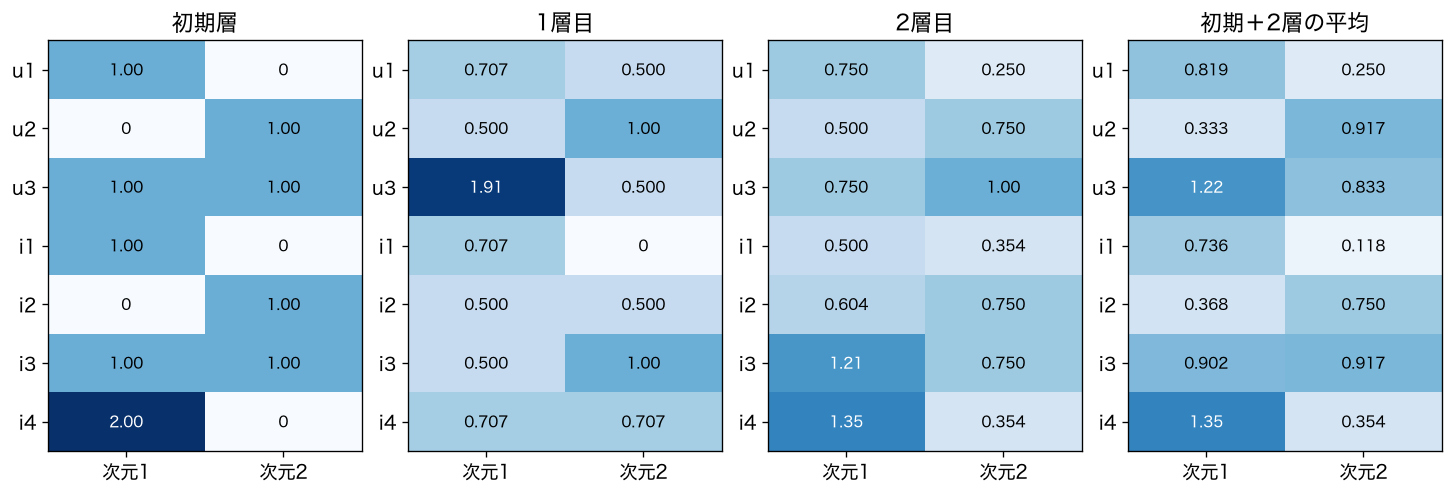

In [7]:
show_math(r"""\(
\begin{aligned}
\mathbf{e}_{u_1}^{(1)}
&=\frac{(1,0)}{\sqrt{2\times1}}+\frac{(0,1)}{\sqrt{2\times2}}
=\left(\frac{1}{\sqrt2},\frac12\right),\\
\mathbf{e}_{i_1}^{(1)}&=\frac{(1,0)}{\sqrt2},\qquad
\mathbf{e}_{i_2}^{(1)}=\frac{(1,0)}2+\frac{(0,1)}2,\\
\mathbf{e}_{u_1}^{(2)}
&=\frac{\mathbf{e}_{i_1}^{(1)}}{\sqrt2}
+\frac{\mathbf{e}_{i_2}^{(1)}}2
=\left(\frac12+\frac14,\frac14\right)
=\left(\frac34,\frac14\right),\\
\mathbf{e}_{u_1}&=\frac{(1,0)+(1/\sqrt2,1/2)+(3/4,1/4)}3
\approx(0.819,0.250).
\end{aligned}
\)""")

E0 = np.array([[1, 0], [0, 1], [1, 1], [1, 0], [0, 1], [1, 1], [2, 0]], dtype=float)
E1 = A_norm @ E0
E2 = A_norm @ E1
E_final = (E0 + E1 + E2) / 3
pprint({"u1の最終埋め込み": E_final[0]})

fig, axes = plt.subplots(1, 4, figsize=(12, 4), layout="constrained")
for ax, embeddings, title in zip(axes, (E0, E1, E2, E_final),
                                 ("初期層", "1層目", "2層目", "初期＋2層の平均")):
    heatmap(ax, embeddings, nodes, ["次元1", "次元2"], title, vmax=2)
save_svg(fig, "03_embedding_propagation.svg")

### 2.6 購入済みの商品を上位にするBPR損失

購入済み$i$と未観測$j$のスコア差を$\Delta$とする。シグモイド関数$\sigma$を使う順位損失は、次の順に変形できる。未観測は「嫌い」を意味せず、将来の購入を含む可能性もある。

<IPython.core.display.Latex object>

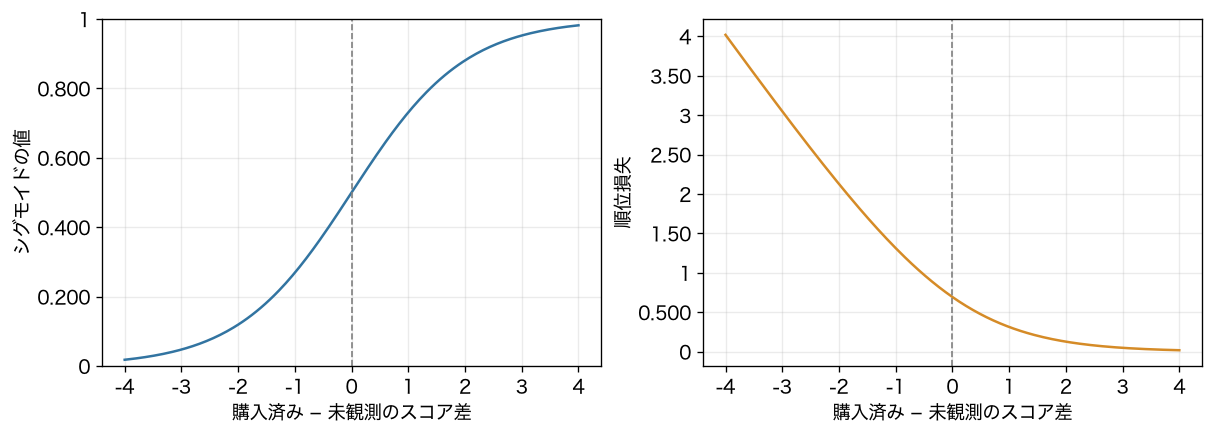

In [8]:
show_math(r"""\(
\begin{aligned}
\Delta&=\hat y_{ui}-\hat y_{uj},\qquad
\sigma(\Delta)=\frac{1}{1+e^{-\Delta}},\\
\ell(\Delta)&=-\log\sigma(\Delta)
=-\log\frac{1}{1+e^{-\Delta}}
=\log(1+e^{-\Delta}),\\
\ell(0)&=\log(1+1)=\log2\approx0.693,\\
\mathcal{J}&=\frac{1}{|\mathcal{B}|}\sum_{(u,i,j)\in\mathcal{B}}
\left[\ell(\Delta)+\lambda
\left(\|\mathbf{e}^{(0)}_u\|^2+\|\mathbf{e}^{(0)}_i\|^2
+\|\mathbf{e}^{(0)}_j\|^2\right)\right].
\end{aligned}
\)""")

delta = np.linspace(-4, 4, 201)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.50), layout="constrained")
axes[0].plot(delta, 1 / (1 + np.exp(-delta)), color=COLORS[0])
axes[0].set(ylabel="シグモイドの値", ylim=(0, 1))
axes[1].plot(delta, np.logaddexp(0, -delta), color=COLORS[1])
axes[1].set(ylabel="順位損失")
for ax in axes:
    ax.set(xlabel="購入済み − 未観測のスコア差")
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.grid(alpha=0.250)
save_svg(fig, "04_bpr_loss.svg")

図4では、購入済みのスコアが高いほど順位損失が小さい。$\mathcal{B}$は更新に使う組の集合、$\lambda$は埋め込みの大きさを抑える強さである。LightGCNは初期の埋め込み、本文のNGCFは各層を結合した埋め込みを正則化する。

## 3. Pythonで学習し、推薦を評価する

本文ではデータ処理を`Dataset`、モデルを`models`、学習と評価を`Trainer`・`Evaluator`に分けている。ここでは計算を追える短い実装にまとめる。小規模なので密行列を使い、NGCFのDropoutは省く。実データ向けの疎行列処理や保存機能は本書の実装を参照できる。

### 3.1 NGCFの実装

比較の基準となる行列分解を`BPR`として用意し、NGCFの集約・要素積・正規化・結合を実装する。

In [9]:
class BPR(nn.Module):
    """ユーザーと商品のIDに対応する埋め込みを学ぶ行列分解。"""

    def __init__(self, purchase, dim=8):
        super().__init__()
        self.n_users, self.n_items = purchase.shape
        self.embedding = nn.Parameter(
            torch.randn(self.n_users + self.n_items, dim) * 0.100
        )
        R_tensor = torch.as_tensor(purchase, dtype=torch.float32)
        adjacency = torch.zeros(self.n_users + self.n_items,
                                self.n_users + self.n_items)
        adjacency[:self.n_users, self.n_users:] = R_tensor
        adjacency[self.n_users:, :self.n_users] = R_tensor.T
        self.register_buffer("adjacency", adjacency)

    def forward(self):
        # 推薦スコア用と正則化用の埋め込みを返す。
        return self.embedding, self.embedding


class NGCF(BPR):
    def __init__(self, purchase, dim=8, n_layers=2):
        super().__init__(purchase, dim)
        degree = self.adjacency.sum(dim=1)
        # 行正規化してから、自己ループを加える。
        propagation = self.adjacency / degree.clamp_min(1)[:, None]
        propagation = propagation + torch.eye(len(degree))
        self.register_buffer("propagation", propagation)
        self.linear = nn.ModuleList([nn.Linear(dim, dim) for _ in range(n_layers)])
        self.interaction = nn.ModuleList([nn.Linear(dim, dim) for _ in range(n_layers)])

    def forward(self):
        current = self.embedding
        outputs = [current]
        for linear, interaction in zip(self.linear, self.interaction):
            neighbors = self.propagation @ current
            current = linear(neighbors) + interaction(neighbors * current)
            current = F.leaky_relu(current, negative_slope=0.200)
            current = F.normalize(current, p=2, dim=1)
            outputs.append(current)
        combined = torch.cat(outputs, dim=1)
        return combined, combined

### 3.2 LightGCNの実装

同じ購入行列から対称正規化した隣接行列を作る。伝播後の平均をスコアに使い、初期の埋め込みを正則化に渡す。

In [10]:
class LightGCN(BPR):
    def __init__(self, purchase, dim=8, n_layers=2):
        super().__init__(purchase, dim)
        self.n_layers = n_layers
        degree = self.adjacency.sum(dim=1)
        inverse = degree.clamp_min(1).rsqrt() * (degree > 0)
        normalized = inverse[:, None] * self.adjacency * inverse[None, :]
        self.register_buffer("propagation", normalized)

    def forward(self):
        current = self.embedding
        total = current
        for _ in range(self.n_layers):
            current = self.propagation @ current
            total = total + current
        return total / (self.n_layers + 1), self.embedding

### 3.3 学習データと評価データを分ける

12人・10商品の模擬履歴を作る。各人は二つの商品群のどちらかに属する5商品を順に購入した設定で、最初の3件を学習、次の1件を検証、最後の1件をテストにする。グラフには学習分だけを入れる。

負例は学習時点の未観測商品から選ぶ。検証では学習済み商品を、テストでは学習・検証で観測した商品を候補から除く。Recall@Kは正解商品のうち上位$K$件に入った割合、nDCG@Kは正解の順位も考慮する指標である。

In [11]:
show_math(r"""\(
\begin{aligned}
\operatorname{Recall}@K&=\frac{\sum_{r=1}^{K}h_r}{|T_u|},\qquad
\operatorname{Precision}@K=\frac{\sum_{r=1}^{K}h_r}{K},\\
\operatorname{DCG}@K&=\sum_{r=1}^{K}\frac{h_r}{\log_2(r+1)},\\
\operatorname{IDCG}@K&=\sum_{r=1}^{\min(K,|T_u|)}\frac{1}{\log_2(r+1)},\qquad
\operatorname{nDCG}@K=\frac{\operatorname{DCG}@K}{\operatorname{IDCG}@K}.
\end{aligned}
\)""")

# 正解が1商品で、それが2位にある場合の計算。
show_math(r"""\(
\begin{aligned}
(h_1,h_2)&=(0,1),\qquad |T_u|=1,\\
\operatorname{Recall}@2&=(0+1)/1=1,\qquad
\operatorname{Precision}@2=(0+1)/2=0.500,\\
\operatorname{DCG}@2&=0/\log_2 2+1/\log_2 3\approx0.631,\\
\operatorname{IDCG}@2&=1/\log_2 2=1,\qquad
\operatorname{nDCG}@2\approx0.631/1=0.631.
\end{aligned}
\)""")

rng = np.random.default_rng(123)
n_users, n_items = 12, 10
train = np.zeros((n_users, n_items), dtype=bool)
valid = np.zeros_like(train)
test = np.zeros_like(train)
for u in range(n_users):
    group = 0 if u < n_users // 2 else 5
    ordered = rng.permutation(np.arange(group, group + 5))
    train[u, ordered[:3]] = True
    valid[u, ordered[3]] = True
    test[u, ordered[4]] = True

# 本文と同様、評価対象のユーザー・商品が学習側にあることを確認する。
assert train.any(axis=0).all() and train.any(axis=1).all()
assert not ((train & valid) | (train & test) | (valid & test)).any()
pprint({"学習の組数": int(train.sum()), "検証の組数": int(valid.sum()),
        "テストの組数": int(test.sum())})


@torch.no_grad()
def evaluate(model, seen, truth, k=2):
    """ユーザーごとに計算して、同じ重みで平均する。"""
    model.eval()
    embeddings, _ = model()
    scores = embeddings[:n_users] @ embeddings[n_users:].T
    scores = scores.masked_fill(torch.as_tensor(seen), -torch.inf)
    ranking = scores.topk(k, dim=1).indices.numpy()
    hits = np.take_along_axis(truth, ranking, axis=1)
    discount = 1 / np.log2(np.arange(2, k + 2))
    relevant = truth.sum(axis=1)
    ideal = np.array([discount[:min(k, count)].sum() for count in relevant])
    metrics = {
        f"Recall@{k}": float(np.mean(hits.sum(axis=1) / relevant)),
        f"Precision@{k}": float(hits.mean()),
        f"nDCG@{k}": float(np.mean((hits * discount).sum(axis=1) / ideal)),
    }
    return metrics, scores.numpy(), ranking


def fit(model_class):
    """同じ初期乱数・負例系列・学習条件で、小規模な計算を確認する。"""
    torch.manual_seed(123)
    sampler = np.random.default_rng(123)
    model = model_class(train)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0300)
    user_np, positive_np = np.nonzero(train)
    user = torch.as_tensor(user_np)
    positive = torch.as_tensor(positive_np + n_users)
    negative_pools = [np.flatnonzero(~row) for row in train]
    history = {"loss": [], "recall": []}
    best_recall, stale, best_epoch = -1, 0, 0

    for epoch in range(1, 101):
        model.train()
        # 学習時点の未観測商品から等確率で負例を抽出する。
        negative_np = np.array([sampler.choice(negative_pools[u]) for u in user_np])
        negative = torch.as_tensor(negative_np + n_users)
        embeddings, penalty = model()
        difference = (embeddings[user] *
                      (embeddings[positive] - embeddings[negative])).sum(dim=1)
        regularization = (penalty[user].square().sum(dim=1)
                          + penalty[positive].square().sum(dim=1)
                          + penalty[negative].square().sum(dim=1)).mean()
        # softplus(-差)で、-log(sigmoid(差))を安定して計算する。
        loss = F.softplus(-difference).mean() + 0.00100 * regularization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        validation, _, _ = evaluate(model, train, valid)
        history["loss"].append(loss.item())
        history["recall"].append(validation["Recall@2"])
        if validation["Recall@2"] > best_recall:
            best_recall = validation["Recall@2"]
            best_state = deepcopy(model.state_dict())
            best_epoch, stale = epoch, 0
        else:
            stale += 1
        if stale >= 10:
            break

    # テストはモデル選択に使わず、検証で選んだ状態を復元して評価する。
    model.load_state_dict(best_state)
    metrics, scores, ranking = evaluate(model, train | valid, test)
    return model, history, best_epoch, metrics, scores, ranking

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

{'テストの組数': 12, '学習の組数': 36, '検証の組数': 12}


上式の$T_u$は正解商品の集合、$h_r$は$r$位が正解なら1となる値である。学習では検証Recall@2が10回連続で改善しなければ停止し、最良時点に戻す。以下の小規模例は処理の確認用であり、モデルの優劣を判断する実験ではない。

{'モデル': 'BPR',
 '採用エポック': 16,
 '模擬データのテスト': {'Precision@2': '0.500', 'Recall@2': '1.00', 'nDCG@2': '0.846'},
 '終了エポック': 26}
{'モデル': 'NGCF',
 '採用エポック': 2,
 '模擬データのテスト': {'Precision@2': '0.250', 'Recall@2': '0.500', 'nDCG@2': '0.377'},
 '終了エポック': 12}
{'モデル': 'LightGCN',
 '採用エポック': 4,
 '模擬データのテスト': {'Precision@2': '0.500', 'Recall@2': '1.00', 'nDCG@2': '1.00'},
 '終了エポック': 14}


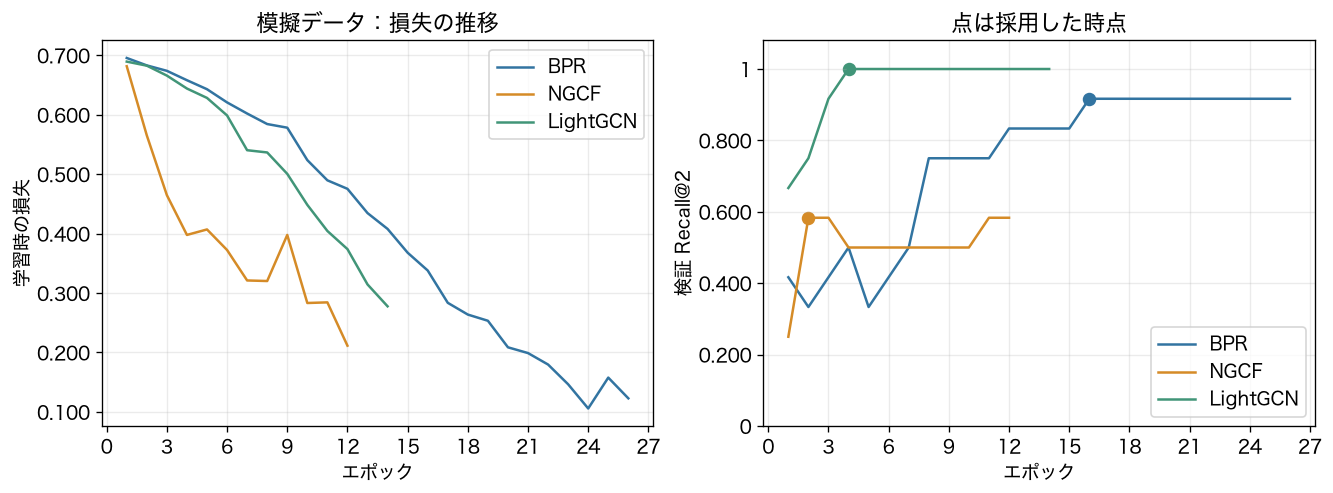

{'u1への推薦上位2件': [2, 8], 'テストの正解商品': [2]}


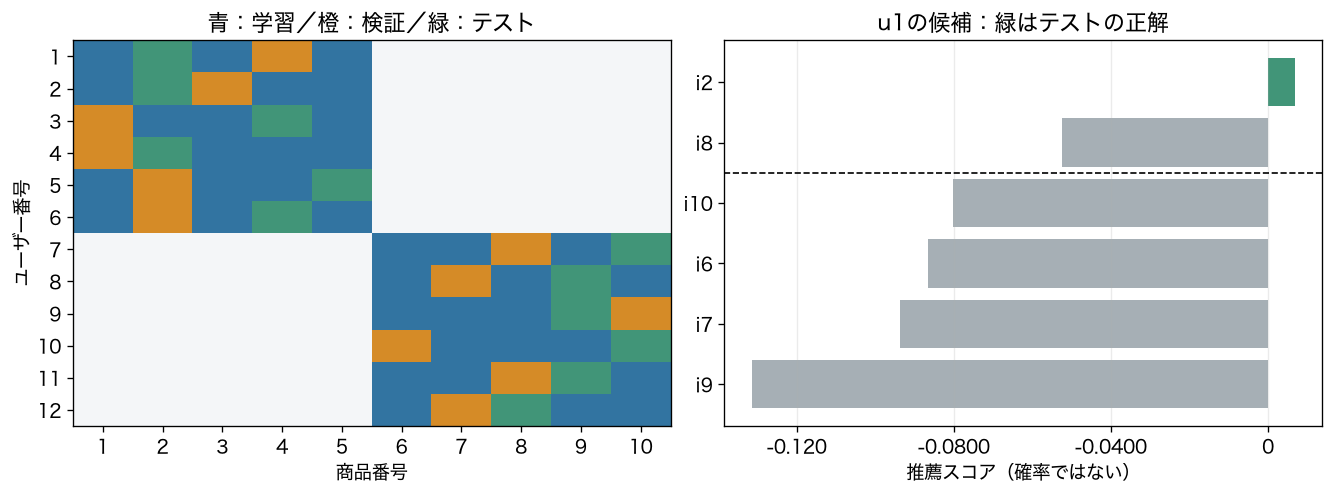

In [12]:
results = {}
for model_class in (BPR, NGCF, LightGCN):
    results[model_class.__name__] = fit(model_class)
    _, history, best_epoch, metrics, _, _ = results[model_class.__name__]
    pprint({"モデル": model_class.__name__, "採用エポック": best_epoch,
            "終了エポック": len(history["loss"]),
            "模擬データのテスト": {key: sig3(value) for key, value in metrics.items()}})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for (name, result), color in zip(results.items(), COLORS):
    _, history, best_epoch, _, _, _ = result
    epochs = np.arange(1, len(history["loss"]) + 1)
    axes[0].plot(epochs, history["loss"], color=color, label=name)
    axes[1].plot(epochs, history["recall"], color=color, label=name)
    axes[1].scatter(best_epoch, history["recall"][best_epoch - 1], color=color, s=50)
axes[0].set(ylabel="学習時の損失", title="模擬データ：損失の推移")
axes[1].set(ylabel="検証 Recall@2", ylim=(0, 1.08), title="点は採用した時点")
for ax in axes:
    ax.set_xlabel("エポック")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.250)
    ax.legend()
save_svg(fig, "05_training_curves.svg")

# ユーザー1人の推薦を、正解とともに読む。
_, _, _, _, scores, ranking = results["LightGCN"]
target_user = 0
candidates = np.flatnonzero(~(train | valid)[target_user])
candidate_scores = scores[target_user, candidates]
candidate_order = np.argsort(-candidate_scores, kind="stable")
candidates = candidates[candidate_order]
candidate_scores = candidate_scores[candidate_order]
pprint({"u1への推薦上位2件": (ranking[target_user] + 1).tolist(),
        "テストの正解商品": (np.flatnonzero(test[target_user]) + 1).tolist()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
stage = train.astype(int) + 2 * valid + 3 * test
axes[0].imshow(stage, cmap=plt.matplotlib.colors.ListedColormap(
    ["#F4F6F8", COLORS[0], COLORS[1], COLORS[2]]), vmin=0, vmax=3, aspect="auto")
axes[0].set(xticks=range(n_items), xticklabels=range(1, n_items + 1),
            yticks=range(n_users), yticklabels=range(1, n_users + 1),
            xlabel="商品番号", ylabel="ユーザー番号", title="青：学習／橙：検証／緑：テスト")
bar_colors = [COLORS[2] if test[target_user, i] else "#A6AFB5" for i in candidates]
axes[1].barh(range(len(candidates)), candidate_scores, color=bar_colors)
axes[1].set(yticks=range(len(candidates)), yticklabels=[f"i{i + 1}" for i in candidates],
            xlabel="推薦スコア（確率ではない）", title="u1の候補：緑はテストの正解")
axes[1].invert_yaxis()
axes[1].xaxis.set_major_locator(MaxNLocator(4))
axes[1].axhline(1.50, color="black", linestyle="--", linewidth=1)
axes[1].grid(axis="x", alpha=0.250)
save_svg(fig, "06_recommendations.svg")

図5の損失は負例の抽出で上下し、正則化も含むため、モデル間の数値だけで性能を比べない。図6では学習・検証の購入商品が推薦候補から外れている。点線より上が推薦する2件である。

## 4. 本文の比較結果をどう読むか

本章ではOnline Retailの返品などを除き、同じ顧客・商品の初回購入を残す。接続数が5件未満の顧客・商品を除き、請求書が3件以上残る顧客を請求書単位で時刻順に分割する。前処理後は1,884顧客、2,985商品、197,104組である。

以下は本文掲載値を図示したもので、上の模擬データの実行結果ではない。総時間はApple M2 ProのCPUで、読込・前処理・学習・評価を含む。

{'テスト Recall@10': {'BPR': '0.0344', 'LightGCN': '0.0403', 'NGCF': '0.0391'},
 'テスト nDCG@10': {'BPR': '0.0458', 'LightGCN': '0.0526', 'NGCF': '0.0493'},
 '総時間（分）': {'BPR': '0.790', 'LightGCN': '6.87', 'NGCF': '9.00'}}


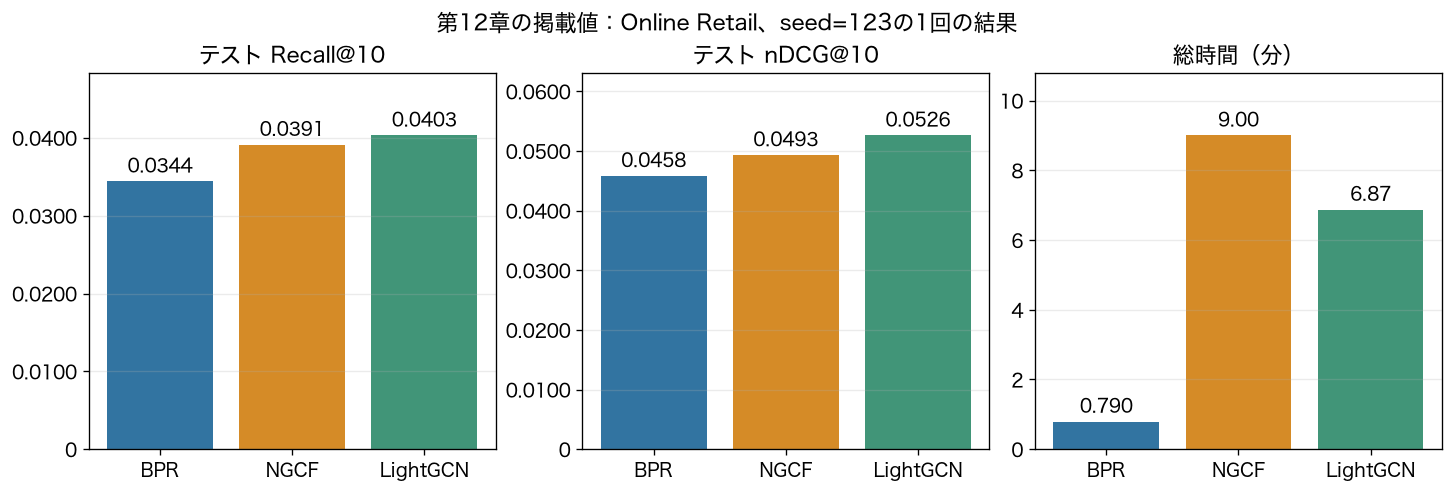

In [13]:
# 出典：doc/12/12_main.tex「BPR・NGCF・LightGCNの比較」の掲載値。
names = ["BPR", "NGCF", "LightGCN"]
book_results = {
    "テスト Recall@10": np.array([0.0344, 0.0391, 0.0403]),
    "テスト nDCG@10": np.array([0.0458, 0.0493, 0.0526]),
    "総時間（分）": np.array([0.790, 9.00, 6.87]),
}
pprint({metric: {name: sig3(value) for name, value in zip(names, values)}
        for metric, values in book_results.items()})

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, (metric, values) in zip(axes, book_results.items()):
    bars = ax.bar(names, values, color=COLORS)
    ax.bar_label(bars, labels=[sig3(value) for value in values], padding=4)
    ax.set(title=metric, ylim=(0, float(values.max()) * 1.20))
    ax.grid(axis="y", alpha=0.250)
fig.suptitle("第12章の掲載値：Online Retail、seed=123の1回の結果")
save_svg(fig, "07_book_comparison.svg")

この条件ではLightGCNの指標が最も高いが、BPRより時間がかかる。乱数を固定した1回の結果であり、常に同じ差が出るとは限らない。対象の絞り込みに全期間を使い、学習にないユーザー・商品を評価から除くため、新規ユーザーへの性能も示していない。

実務では履歴件数ごとの精度、人気商品への偏り、応答時間を確認する。そのうえで対象を限定したA/Bテストを行い、クリック率や購入率を比べる。オフラインの推薦指標が高くても、売上増加が確認されたことにはならない。

## 結論

この記事では、購入関係をグラフで表し、NGCFとLightGCNで埋め込みを学習して、未観測の商品を推薦する流れを紹介した。

NGCFは集約と要素積を使い、LightGCNは伝播と各層の平均を使う。モデルの構成に加え、データの分割と推薦候補の除外も結果を左右する。

[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)第12章では、実データの前処理から疎行列の構築、学習制御、結果の解釈まで説明している。全体のコードは[サポートページ](https://github.com/gihyo-book/marketing_science_book)で参照できる。

参考文献：Wang et al., [Neural Graph Collaborative Filtering](https://arxiv.org/abs/1905.08108), 2019；He et al., [LightGCN](https://arxiv.org/abs/2002.02126), 2020。本文の比較に用いたデータはD. Chen, [Online Retail](https://doi.org/10.24432/C5BW33), UCI, 2015である。